In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/Housing.csv')

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset Loaded Successfully!
Dataset Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [12]:
median_price = df['price'].median()

df['price_class'] = (df['price'] > median_price).astype(int)

print("Median Price:", median_price)

print("\nClass Distribution:")
print(df['price_class'].value_counts())

print("\nUpdated Dataset:")
df[['price', 'price_class']].head(10)

Median Price: 4340000.0

Class Distribution:
price_class
0    275
1    270
Name: count, dtype: int64

Updated Dataset:


,price,price_class
0,13300000,1
1,12250000,1
2,12250000,1
3,12215000,1
4,11410000,1
5,10850000,1
6,10150000,1
7,10150000,1
8,9870000,1
9,9800000,1


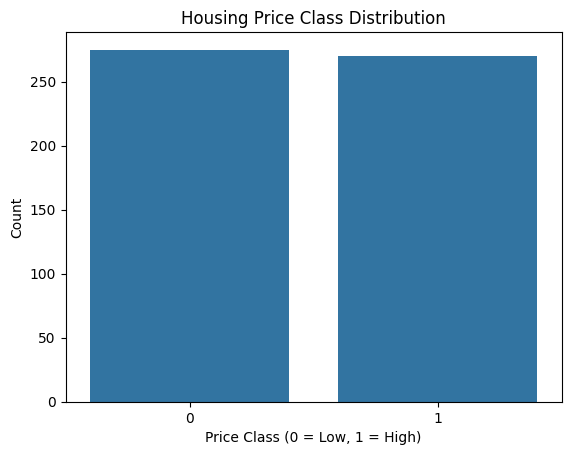

In [13]:
sns.countplot(x='price_class', data=df)

plt.title('Housing Price Class Distribution')
plt.xlabel('Price Class (0 = Low, 1 = High)')
plt.ylabel('Count')

plt.show()

In [14]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
df.describe()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
 13  price_class       545 non-null    int64 
dtypes: int64(7), object(7)
memory usage: 59.7+ KB
None

Missing Values:
price               0
area                0
bedrooms            0

,price,area,bedrooms,bathrooms,stories,parking,price_class
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578,0.495413
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586,0.500438
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000,1.000000


In [15]:
X = df[['area', 'bedrooms', 'bathrooms',
        'stories', 'parking']]

y = df['price_class']

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features:
   area  bedrooms  bathrooms  stories  parking
0  7420         4          2        3        2
1  8960         4          4        4        3
2  9960         3          2        2        2
3  7500         4          2        2        3
4  7420         4          1        2        2

Target Variable:
0    1
1    1
2    1
3    1
4    1
Name: price_class, dtype: int64

Feature Shape: (545, 5)
Target Shape: (545,)


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target:")
print(y_train.value_counts())

print("\nTesting Target:")
print(y_test.value_counts())

Training Data: (436, 5)
Testing Data: (109, 5)

Training Target:
price_class
0    220
1    216
Name: count, dtype: int64

Testing Target:
price_class
0    55
1    54
Name: count, dtype: int64


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed Successfully!")

print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

Feature Scaling Completed Successfully!
Training Data Shape: (436, 5)
Testing Data Shape: (109, 5)


In [18]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

print("\nModel Intercept:")
print(model.intercept_)

print("\nModel Coefficients:")
print(model.coef_)

Logistic Regression Model Trained Successfully!

Model Intercept:
[0.18923659]

Model Coefficients:
[[1.20502541 0.16915791 0.59484991 0.84351365 0.22058958]]


In [19]:
y_pred = model.predict(X_test_scaled)

print("Actual Values:")
print(y_test.values[:10])

print("\nPredicted Values:")
print(y_pred[:10])

print("\nPrediction Completed Successfully!")

Actual Values:
[1 1 0 1 0 1 0 0 1 0]

Predicted Values:
[1 1 0 1 0 1 0 0 1 0]

Prediction Completed Successfully!


Confusion Matrix:
[[44 11]
 [ 9 45]]


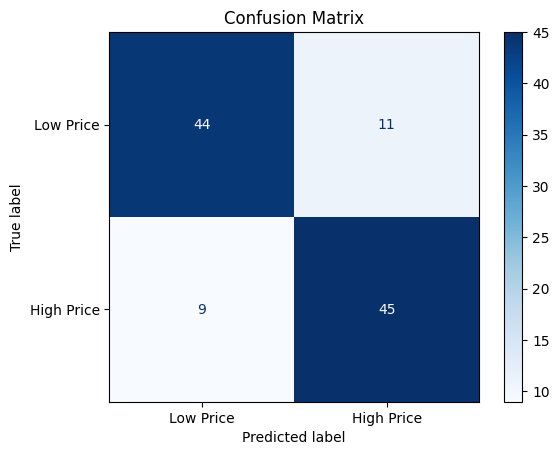

In [20]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Low Price', 'High Price']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

In [21]:
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.8165137614678899
Precision: 0.8035714285714286
Recall: 0.8333333333333334
F1 Score: 0.8181818181818182


In [22]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_auc_score, roc_curve

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

specificity = tn / (tn + fp)

y_prob = model.predict_proba(X_test_scaled)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("Specificity:", specificity)
print("ROC-AUC Score:", roc_auc)

Specificity: 0.8
ROC-AUC Score: 0.8904040404040404


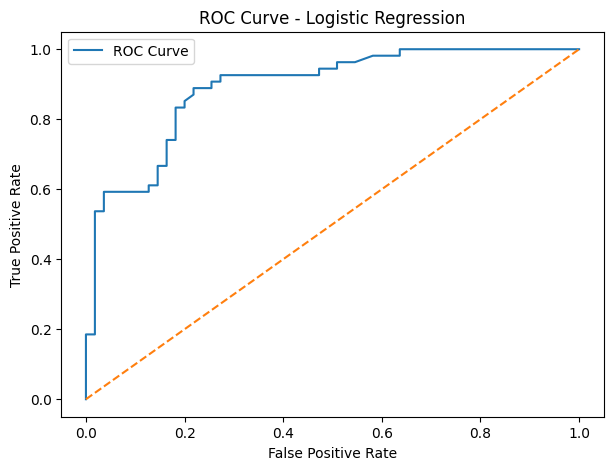

In [23]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7,5))

plt.plot(fpr, tpr, label='ROC Curve')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')

plt.legend()
plt.show()

In [24]:
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

thresholds = [0.3, 0.5, 0.7]

for t in thresholds:
    y_threshold = (y_prob >= t).astype(int)

    print("\nThreshold:", t)
    print("Accuracy:", accuracy_score(y_test, y_threshold))
    print("Precision:", precision_score(y_test, y_threshold))
    print("Recall:", recall_score(y_test, y_threshold))
    print("F1 Score:", f1_score(y_test, y_threshold))


Threshold: 0.3
Accuracy: 0.7522935779816514
Precision: 0.684931506849315
Recall: 0.9259259259259259
F1 Score: 0.7874015748031497

Threshold: 0.5
Accuracy: 0.8165137614678899
Precision: 0.8035714285714286
Recall: 0.8333333333333334
F1 Score: 0.8181818181818182

Threshold: 0.7
Accuracy: 0.7339449541284404
Precision: 0.8205128205128205
Recall: 0.5925925925925926
F1 Score: 0.6881720430107527


In [25]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Low Price', 'High Price']
))

Classification Report:
              precision    recall  f1-score   support

   Low Price       0.83      0.80      0.81        55
  High Price       0.80      0.83      0.82        54

    accuracy                           0.82       109
   macro avg       0.82      0.82      0.82       109
weighted avg       0.82      0.82      0.82       109



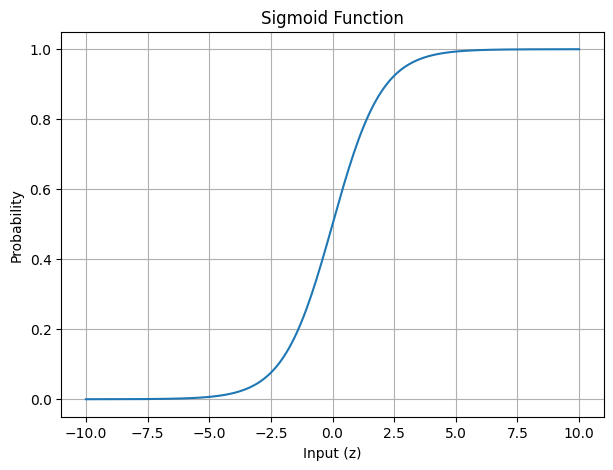

In [26]:
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-10, 10, 200)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(7,5))
plt.plot(z, sigmoid)
plt.title('Sigmoid Function')
plt.xlabel('Input (z)')
plt.ylabel('Probability')
plt.grid(True)
plt.show()

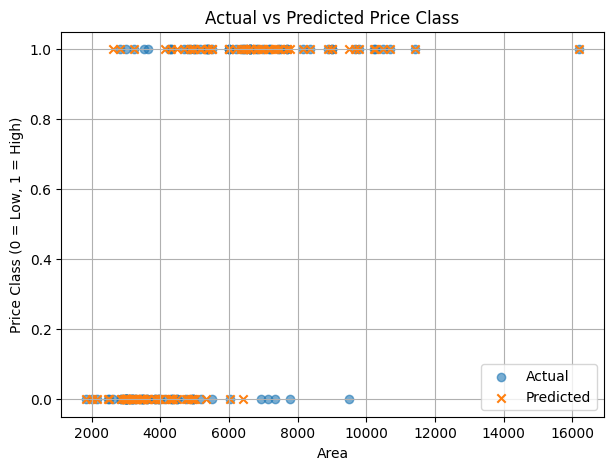

In [27]:
plt.figure(figsize=(7,5))

plt.scatter(
    X_test['area'],
    y_test,
    label='Actual',
    alpha=0.6
)

plt.scatter(
    X_test['area'],
    y_pred,
    label='Predicted',
    marker='x'
)

plt.xlabel('Area')
plt.ylabel('Price Class (0 = Low, 1 = High)')
plt.title('Actual vs Predicted Price Class')
plt.legend()
plt.grid(True)

plt.show()

In [28]:
new_house = pd.DataFrame({
    'area': [3000],
    'bedrooms': [3],
    'bathrooms': [2],
    'stories': [2],
    'parking': [1]
})

new_house_scaled = scaler.transform(new_house)

prediction = model.predict(new_house_scaled)

print("New House Details:")
print(new_house)

if prediction[0] == 1:
    print("\nPredicted Class: High Price")
else:
    print("\nPredicted Class: Low Price")

New House Details:
   area  bedrooms  bathrooms  stories  parking
0  3000         3          2        2        1

Predicted Class: High Price


In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (436, 5)
Testing Data: (109, 5)


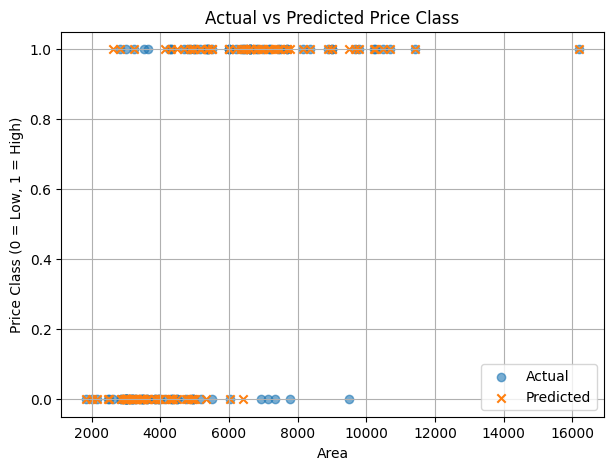

In [31]:
plt.figure(figsize=(7,5))

plt.scatter(
    X_test['area'],
    y_test,
    label='Actual',
    alpha=0.6
)

plt.scatter(
    X_test['area'],
    y_pred,
    label='Predicted',
    marker='x'
)

plt.xlabel('Area')
plt.ylabel('Price Class (0 = Low, 1 = High)')
plt.title('Actual vs Predicted Price Class')
plt.legend()
plt.grid(True)

plt.show()